In [1]:
import numpy as np
import pandas as pd

#инструменты пайплайна и валидации
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

#инструменты предобработки
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

#модель классификации
from sklearn.neighbors import KNeighborsClassifier

#бизнес-метрики качества
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

Подключение необходимых библиотек: 
- numpy и pandas - для математических вычислений, загрузки и обработки табличных данных; 
- Pipeline и ColumnTransformer - для создания единого конвейера обработки и защиты от утечки данных; 
- train_test_split - для разделения на обучающую и тестовую выборки; 
- StratifiedKFold и GridSearchCV - для стратифицированной кросс-валидации и подбора гиперпараметров; 
- SimpleImputer - для заполнения пропусков; 
- StandardScaler и OneHotEncoder - для масштабирования числовых и кодирования категориальных признаков; 
- KNeighborsClassifier - алгоритм классификации (метод k-ближайших соседей); 
- confusion_matrix, classification_report и roc_auc_score - для расчета матрицы ошибок, метрик Precision/Recall/F1 и площади под ROC-кривой.

1. Инженерия данных и конвейеры обработки

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = df.drop("customerID", axis=1)

#конвертируем TotalCharges в числовой формат
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

#кодируем целевую переменную: Yes=1 (ушел), No=0 (остался)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

#баланс классов (целевая переменная - Churn: 0 - остались, 1 - ушли)
class_counts = df["Churn"].value_counts(normalize=True) * 100
print(f"Баланс классов: \n Остались (0) - {class_counts[0]:.1f}%\nУшли (1) - {class_counts[1]:.1f}%")

#делим выборку
X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(df.columns)

Баланс классов: 
 Остались (0) - 73.5%
Ушли (1) - 26.5%
Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')


Выполнение первичной очистки и подготовки данных
- Был удален столбец "customerID", поскольку он содержит уникальные идентификаторы клиентов и не несет пользы для предсказания модели
- Столбец "TotalCharges" был преобразован в числовой формат, поскольку его тип данных был string и также содержал пустые строки.
- Проведено кодирование целевой переменной "Churn", "Yes" и "No" заменены на 1 (клиент ушел) и 0 (клиент остался)
- Данные разделены на обучающую (80%) и тестовую (20%) выборки

73.5% клиентов остались, а 26.5% ушли.
Клиентов, которые лояльны компании, почти в три раза больше, чем тех, кто ушел. Из-за этого дисбаланса использование стандартной метрики Accuracy будет неинформативным, поскольку модель будет склонна чаще предсказывать "остался" и получать 73.5% точности, но быть бесполезной для бизнеса.


In [3]:
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
                        'PhoneService', 'MultipleLines', 'InternetService',
                        'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                        'TechSupport', 'StreamingTV', 'StreamingMovies',
                        'Contract', 'PaperlessBilling', 'PaymentMethod']

#ветка 1: обработка чисел
numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())]
)

#ветка 2: обработка категорий (текста)
categorical_transformer = Pipeline(
    steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
         ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

#1+2
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

#итоговый конвейер: предобработка -> модель
clf_pipline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier())
    ]
)

Создается единый конвейер обработки данных (Pipeline), который разделяет признаки на числовые и категориальные. Числовые признаки (tenure, MonthlyCharges, TotalCharges) проходят через заполнение пропусков медианой и стандартизацию. Категориальные признаки (16 столбцов) заполняются наиболее частым значением и кодируются через One-Hot Encoding. Затем этот препроцессор объединяется с алгоритмом классификации в одну структуру, предотвращая утечку данных из тестовой выборки в обучающую.

2. Кросс-валидация и гиперпараметры

In [4]:

param_grid = {
    "classifier__n_neighbors": [3,5,9],
    "classifier__weights":["uniform", "distance"]
}

#5-fold кросс-валидация
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
#сбор всего в одно
grid_search = GridSearchCV(
    estimator=clf_pipline,
    param_grid=param_grid,
    cv = cv_strategy,
    scoring="roc_auc",
    n_jobs=1
)
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
print(f'\nЛучшие параметры алгоритма: {grid_search.best_params_}')


Лучшие параметры алгоритма: {'classifier__n_neighbors': 9, 'classifier__weights': 'uniform'}


Выполняется подбор лучших гиперпараметров для модели с использованием 5-фолдовой стратифицированной кросс-валидации.

Результат показал, что лучшие параметры - 9 соседей и равные веса. Это значит, что для данного датасета и задачи прогнозирования оттока модель работает лучше всего, когда она учитывает мнение 9 ближайших соседей и при этом придает всем им одинаковую значимость.

3. Оценка бизнес-метрик и визуализация

In [5]:
#предскажем 0 или 1
y_pred = best_model.predict(X_test)
#предсказание вероятностей от 0.0 до 1.0 (для ROC-AUC)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("---- Матрица ошибок -----")
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Истинно отрицательные (TN - клиент остался, и по предсказанию остался) {conf_matrix[0][0]}")
print(f"Ложноположительные (FP - клиент остался, но по предсказанию ушел) {conf_matrix[0][1]}")
print(f"Ложноотрицательные (FN - клиент ушел, но по предсказанию остался) {conf_matrix[1][0]}")
print(f"Истинно положительные (TP - клиент ушел, и по предсказанию ушел) {conf_matrix[1][1]}")

print("---- Отчет по метрикам ----")
print(classification_report(y_test, y_pred, target_names=["Остался (0)", "Ушел (1)"]))

roc_auc = roc_auc_score(y_test, y_proba)
print(f"Площадь под кривой ROC-AUC: {roc_auc:.4f}")


---- Матрица ошибок -----
Истинно отрицательные (TN - клиент остался, и по предсказанию остался) 881
Ложноположительные (FP - клиент остался, но по предсказанию ушел) 154
Ложноотрицательные (FN - клиент ушел, но по предсказанию остался) 155
Истинно положительные (TP - клиент ушел, и по предсказанию ушел) 219
---- Отчет по метрикам ----
              precision    recall  f1-score   support

 Остался (0)       0.85      0.85      0.85      1035
    Ушел (1)       0.59      0.59      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409

Площадь под кривой ROC-AUC: 0.8138


- TN (истинно отрицательные): Модель верно предсказала 881 раз, что клиент останется
- FP (ложноположительные): Модель ошиблась 154 раза, предсказав уход, хотя клиент остался
- FN (ложноотрицательные): Модель ошиблась 155 раз, предсказав, что клиент останется, хотя он ушел
- TP (истинно положительные): Модель верно предсказала уход клиента 219 раз

Для класса "Остался":
- Precision 0.85: из всех, кого модель назвала оставшимися, 85% действительно остались.
- Recall 0.85: из всех реально лояльных клиентов модель смогла найти 85%.
- F1-score 0.85: общая оценка, модель хорошо работает с большинством.

Для класса "Ушел":
- Precision 0.59: из всех, кого модель назвала уходящими, только 59% действительно ушли.
- Recall 0.59: из всех, кто реально ушел, модель смогла выявить только 59%, 41% ушедших клиентов модель пропустила.
- F1-score 0.59: общая оценка, значение ниже 0.7 указывает на то, что модель справляется с поиском оттока клиентов посредственно.

ROC-AUC = 0.8138. Это значит, что модель умеет правильно ранжировать клиентов по риску оттока: если взять наугад одного ушедшего и одного лояльного абонента, то в 81% случаев модель поставит уходящего клиента выше по шкале риска, чем оставшегося.

Вывод: Модель отлично находит тех, кто останется, но плохо справляется с главной бизнес-задачей - поиском тех, кто уйдет. В задаче удержания клиентов ошибка FN (пропустить уходящего) почти всегда стоит бизнесу дороже, чем ошибка FP (лишняя скидка лояльному). Потеря 155 клиентов (FN) нанесет больший финансовый ущерб, чем 154 ненужных звонка или скидки (FP).

Предсказание ежемесячного платежа

In [7]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

df_reg = df.dropna(subset=["TotalCharges"]).copy()


X_reg = df_reg[["tenure", "TotalCharges", "SeniorCitizen"]]
y_reg = df_reg["MonthlyCharges"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

reg_pipline = Pipeline(
    [("scaler", StandardScaler()), ("knn_reg", KNeighborsRegressor())]
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
param_dist={
    "knn_reg__n_neighbors": np.arange(3,10,2),
    "knn_reg__weights": ["uniform", "distance"]
}

random_search = RandomizedSearchCV(
    estimator=reg_pipline,
    param_distributions=param_dist,
    n_iter=10,
    cv=kf,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_r, y_train_r)
best_reg =  random_search.best_estimator_
print(f'\nЛучшие параметры алгоритма: {random_search.best_params_}')

d:\#вуз\4 курс\Искусственный интеллект\AI\lab3\.venv\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 8 is smaller than n_iter=10. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(



Лучшие параметры алгоритма: {'knn_reg__weights': 'distance', 'knn_reg__n_neighbors': np.int64(7)}


Предсказание ежемесячного платежа клиента (MonthlyCharges) на основе его стажа (tenure), общей суммы платежей (TotalCharges) и статуса пенсионера (SeniorCitizen).

Лучшими параметрами оказались учитывание мнения 7 ближайших соседей и применение взвешивания по расстоянию. Это значит, что при расчете прогноза вклад каждого из 7 соседей зависит от степени его схожести с целевым клиентом: чем ближе сосед в пространстве признаков, тем больший вес его данные имеют при формировании итоговой суммы.


In [7]:
y_pred_r = best_reg.predict(X_test_r)
def smape(y_test, y_pred):
    return 100* np.mean(
        2 * np.abs(y_pred-y_test)/(np.abs(y_test)+np.abs(y_pred))
    )
mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_r, y_pred_r)
smape_value = smape(y_test_r, y_pred_r)

print("---- Отчет по метрикам регрессии -----")
print(f"MSE (квадратные $) {mse:,.0f}")
print(f"RMSE ($) {rmse:,.0f}")
print(f"MAE (Средняя ошибка) {mae:,.2f}")
print(f"SMAPE (ошибка в %) {smape_value:.2f}")

---- Отчет по метрикам регрессии -----
MSE (квадратные $) 9
RMSE ($) 3
MAE (Средняя ошибка) 1.94
SMAPE (ошибка в %) 3.22


В данном блоке выполняется оценка качества обученной регрессионной модели на независимой тестовой выборке

RMSE 3 доллара - стандартное отклонение ошибки составляет 3 доллара. Это значит, что если модель предсказала клиенту платеж в $50, то с высокой долей вероятности реальный платеж этого клиента будет лежать в диапазоне от 47 до 53 долларов

MAE 1.94 доллара - модель ошибается на 1.94 доллара при предсказании ежемесячного платежа. Учитывая, что платежи в датасете варьируются от 18 до 119 долларов, это высокая точность

SMAPE 3.22% - модель отклоняется от действительности на 3.22% от реальной суммы платежа.

Вывод: Модель продемонстрировала высокую точность. Анализ метрик показал, что модель не делает грубых ошибок в предсказаниях, средняя ошибка в 1.94 доллара значит, что прогнозы модели можно использовать в реальных бизнес-процессах.


Визуальный анализ

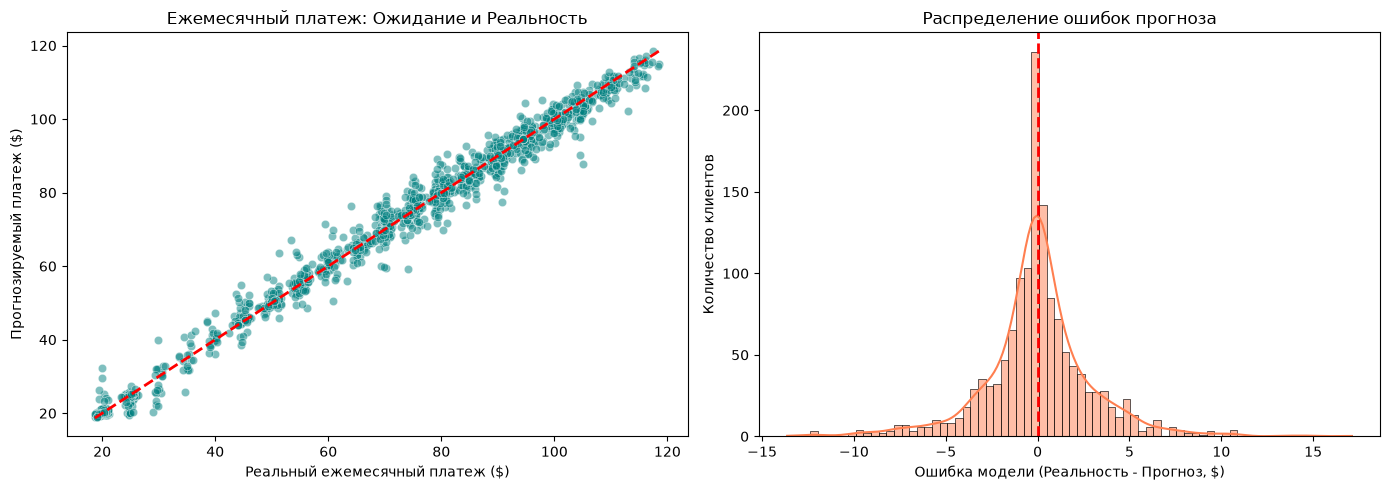

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1,2, figsize = (14,5))

# 1 График: Факт vs Прогноз
sns.scatterplot(x=y_test_r, y=y_pred_r, alpha=0.5, color="teal", ax=axes[0])
y_min = min(y_test_r.min(), y_pred_r.min())
y_max = max(y_test_r.max(), y_pred_r.max())
axes[0].plot(
    [y_min, y_max], [y_min, y_max], 'r--', lw=2
)
axes[0].set_title("Ежемесячный платеж: Ожидание и Реальность")
axes[0].set_xlabel("Реальный ежемесячный платеж ($)")
axes[0].set_ylabel("Прогнозируемый платеж ($)")

# 2 График: Распределение ошибок
residuals = y_test_r - y_pred_r
sns.histplot(residuals, kde=True, color='coral', ax=axes[1])
axes[1].axvline(x=0, color='red', linestyle='--', lw=2) #линия нулевой ошибки
axes[1].set_title("Распределение ошибок прогноза")
axes[1].set_xlabel("Ошибка модели (Реальность - Прогноз, $)")
axes[1].set_ylabel("Количество клиентов")

plt.tight_layout()
plt.show()

1. Первый график визуализирует сопоставление реальных и предсказанных значений ежемесячного платежа. Чем плотнее точки прилегают к красной линии, тем выше точность модели, так как это означает, что прогноз практически равен фактической сумме. Точки на графике очень плотно сгруппированы у красной линии, разброс точек в стороны минимален. Это показывает, что модель отлично справляется с задачей: она одинаково точно предсказывает как низкие платежи, так и высокие. Сильных выбросов, где модель совсем не угадала сумму, практически нет.

2. Второй график визуализирует разницу между реальным ежемесячным платежом и значением, которое предсказала модель. Наивысшая точка гистограммы и кривой находится на красной пунктирной линии, соответствующей ошибке в 0 долларов. Это значит, что модель не склонна постоянно занижать или завышать прогнозируемые суммы платежей. Подавляющее большинство ошибок сосредоточено в очень узком диапазоне от -5 до +5 долларов. Значения от -10 до -15 и от 10 до 15 долларов практически незаметны, т.е. ситуации, когда модель ошибается на 10-15 долларов, встречаются крайне редко.

Вывод по прогнозам ежемесячных платежей: модель предсказывает ежемесячный платеж с высокой точностью. Бизнес-применение: компания может использовать эти прогнозы для расчета ожидаемой выручки и финансового планирования. Кроме того, модель служит инструментом контроля: если фактический ежемесячный платеж клиента существенно отклоняется от прогноза, это служит сигналом для проверки корректности начислений или анализа того, не переплачивает ли абонент за неиспользуемые услуги.

Вывод по прогнозу оттока клиентов

1. Ошибка 1 рода (FP 154 клиента). Модель спрогнозировала уход 154 клиентов из 1409, но они остались. Потенциальные убытки: Компания тратит маркетинговый бюджет на программы удержания (предоставление скидок, бесплатных опций, звонки менеджеров) для лояльных клиентов, которые и так планировали продолжать пользоваться услугами. Это прямые, но относительно небольшие финансовые издержки.

2. Ошибка 2 рода (FN 155 клиентов). Модель спрогнозировала, что 155 клиентов останутся, но они ушли. Потенциальные убытки: Компания теряет абонента и весь связанный с ним будущий доход. Потеря клиента стоит бизнесу дороже, чем траты на удержание и так лояльных клиентов.

Поскольку финансовая потеря от ухода клиента (ошибка 2 рода) значительно превышает затраты на предоставление скидки лояльному клиенту (ошибка 1 рода), жесткость алгоритма (баланс Precision/Recall) менять необходимо, нужно сдвинуть баланс в сторону Recall.